# Exercise 1 

In this exercise, we will work with the `winemag-data-130k-v2.csv` data file. This file contains information about wine. The goal is to explore this data using the NLP techniques that we have learnt. For more information about the data file, see this [link](https://www.kaggle.com/datasets/zynicide/wine-reviews/data).

### Exercise 1(a) (2 points)

Load the following libraries as follows:

```
import pandas as pd 
import numpy as np
```

In [1]:
import pandas as pd
import numpy as np

### Exercise 1(b) (2 points)

Read the `csv` file and create a data-frame called `wine_df`.

In [2]:
wine_df = pd.read_csv('DATA/winemag-data-130k-v2.csv')

### Exercise 1(c) (2 points)

Report the number of wine types in the `wine_df` data frame.

In [ ]:
wine_df['variety'].nunique()

### Exercise 1(d) (2 points)

Report the number countries producing wine in the `wine_df` data frame.

In [ ]:
wine_df['country'].nunique()

### Exercise 1(e) (3 points)

Using the `string` library, remove all the punctuation of the `description` column and store the results in another column called `description_clean`.

In [4]:
import string

wine_df['description_clean'] = wine_df['description'].fillna('').str.translate(
    str.maketrans('', '', string.punctuation)
)

### Exercise 1(f) (10 points)

Using the `nltk` library, remove stopwords, pronouns, and the following words: `drink`, `now`, `wine`, `flavor`, and `flavors` from `description_clean` and store in another column called `'description_clean_1'`. 

In [5]:
import nltk
from nltk import pos_tag, word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

nltk.download(['stopwords', 'punkt_tab', 'averaged_perceptron_tagger_eng', 'wordnet'])
stop_words = set(stopwords.words('english'))
remove_words = {'drink', 'now', 'wine', 'flavor', 'flavors'}

def clean_text(text):
    words = word_tokenize(text.lower())
    tagged_words = pos_tag(words)
    return ' '.join(word for word, tag in tagged_words
                    if word not in stop_words and word not in remove_words
                    and tag not in ('PRP', 'PRP$', 'WP', 'WP$'))

wine_df['description_clean_1'] = wine_df['description_clean'].apply(clean_text)

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\bdupey\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\bdupey\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     C:\Users\bdupey\AppData\Roaming\nltk_data...
[nltk_data]   Package averaged_perceptron_tagger_eng is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\bdupey\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


### Exercise 1(g) (10 points)

Perform Lemmatization of `description_clean_1` and store the results in another column called `description_clean_2` in the `wine_df` data frame.

In [6]:
lemmatizer = WordNetLemmatizer()
wine_df['description_clean_2'] = wine_df['description_clean_1'].apply(
    lambda text: ' '.join(lemmatizer.lemmatize(word) for word in text.split())
)

### Exercise 1(h) (5 points)

Based on the results from part 1(g), we see digits in some of the text in `description_clean_2`. Remove all the digits from `description_clean_2` and store the results in another column `description_clean_3` in the `wine_df` data frame.

In [7]:
wine_df['description_clean_3'] = wine_df['description_clean_2'].str.replace(
    r'\d+', '', regex=True
)

### Exercise 1(i) (10 points)

Using the `TfidfVectorizer` function from `sklearn.feature_extraction.text`, convert the `description_clean_3` column into matrix of token counts use `max_features=100` to create the input features, called this matrix `X`. Define `y = wine_df['points']`. Consider the following configuration:

```
tfidf_vectorizer = TfidfVectorizer(
    max_features=100,
    max_df=0.8,  # Remove words that appear in more than 80% of documents
    min_df=5,    # Remove words that appear in fewer than 5 documents
    stop_words='english'
)
```

Then, extract five topics using `LatentDirichletAllocation` with the following configuration:

```
# Initialize LDA with 5 topics
n_topics = 5
lda_model = LatentDirichletAllocation(
    n_components=n_topics,
    random_state=42,
    max_iter=100,
    learning_method='batch'
)
```

Then, print the words associated to each of the topics.

In [8]:
from sklearn.decomposition import LatentDirichletAllocation
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf_vectorizer = TfidfVectorizer(
    max_features=100, max_df=0.8, min_df=5, stop_words='english'
)
X = tfidf_vectorizer.fit_transform(wine_df['description_clean_3'])
y = wine_df['points']
n_topics = 5
lda_model = LatentDirichletAllocation(
    n_components=n_topics, random_state=42, max_iter=100,
    learning_method='batch'
)
lda_features = lda_model.fit_transform(X)
words = np.array(tfidf_vectorizer.get_feature_names_out())
for topic_number, topic in enumerate(lda_model.components_, start=1):
    print(f"Topic {topic_number}: {', '.join(words[topic.argsort()[-10:][::-1]])}")

Topic 1: fruity, pinot, crisp, light, acidity, fruit, bright, vineyard, fresh, texture
Topic 2: cabernet, blackberry, blend, cherry, merlot, oak, sauvignon, chocolate, syrah, tannic
Topic 3: aroma, palate, cherry, berry, black, plum, finish, note, tannin, spice
Topic 4: apple, peach, palate, citrus, finish, pear, white, lemon, aroma, note
Topic 5: fruit, tannin, structure, rich, ripe, wood, year, age, aging, acidity


### Exercise 1(j) (10 points)

Using the `TfidfVectorizer` function from `sklearn.feature_extraction.text`, convert the `description_clean_3` column into matrix of token counts use `max_features=100` to create the input features, called this matrix `X`. Define `y = wine_df['points']`. Consider the following configuration:

```
tfidf_vectorizer = TfidfVectorizer(
    max_features=100,
    max_df=0.8,  # Remove words that appear in more than 80% of documents
    min_df=5,    # Remove words that appear in fewer than 5 documents
    stop_words='english'
)
```

Then, extract five topics using `NMF` with the following configuration:

```
# Initialize NMF with the same number of topics as LDA for comparison
nmf_model = NMF(
    n_components=n_topics,
    random_state=42,
    max_iter=200,
    alpha_W=0,    # Regularization parameter for W
    alpha_H=0,    # Regularization parameter for H
    l1_ratio=0.5    # Balance between L1 and L2 regularization
)
```

In [ ]:
from sklearn.decomposition import NMF

nmf_model = NMF(
    n_components=n_topics, random_state=42, max_iter=200,
    alpha_W=0, alpha_H=0, l1_ratio=0.5
)
nmf_features = nmf_model.fit_transform(X)
for topic_number, topic in enumerate(nmf_model.components_, start=1):
    print(f"Topic {topic_number}: {', '.join(words[topic.argsort()[-10:][::-1]])}")

### Exercise 1(k) (10 points)

Train and evaluate (using `RMSE` as measure of performance) three `LinearRegression` models as follows:

- Using LDA features as input.
- Using NMF features as input.
- Combine LDA + NMF features as input.

Evaluate the three models over a five-fold cross validation strategy.

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, cross_val_score

cv = KFold(n_splits=5, shuffle=True, random_state=42)
combined_features = np.hstack((lda_features, nmf_features))
linear_rmse = {}
for name, features in [('LDA', lda_features), ('NMF', nmf_features),
                       ('LDA + NMF', combined_features)]:
    scores = cross_val_score(
        LinearRegression(), features, y, cv=cv,
        scoring='neg_root_mean_squared_error'
    )
    linear_rmse[name] = -scores.mean()
    print(name, linear_rmse[name])

### Exercise 1(l) (10 points)

Train and evaluate (using `RMSE` as measure of performance) three `RandomForestRegressor` (with `n_estimators=100`, and `max_depth=5`) models as follows:

- Using LDA features as input.
- Using NMF features as input.
- Combine LDA + NMF features as input.

Evaluate the three models over a five-fold cross validation strategy.

In [ ]:
from sklearn.ensemble import RandomForestRegressor

forest_rmse = {}
for name, features in [('LDA', lda_features), ('NMF', nmf_features),
                       ('LDA + NMF', combined_features)]:
    scores = cross_val_score(
        RandomForestRegressor(n_estimators=100, max_depth=5, random_state=42),
        features, y, cv=cv, scoring='neg_root_mean_squared_error'
    )
    forest_rmse[name] = -scores.mean()
    print(name, forest_rmse[name])

### Exercise 1(m) (10 points)

Train and evaluate (using `RMSE` as measure of performance) three `SVR` (with `kernel='poly'`)models as follows:

- Using LDA features as input.
- Using NMF features as input.
- Combine LDA + NMF features as input.

Evaluate the three models over a five-fold cross validation strategy.

In [ ]:
from sklearn.svm import SVR

svr_rmse = {}
for name, features in [('LDA', lda_features), ('NMF', nmf_features),
                       ('LDA + NMF', combined_features)]:
    scores = cross_val_score(
        SVR(kernel='poly'), features, y, cv=cv,
        scoring='neg_root_mean_squared_error'
    )
    svr_rmse[name] = -scores.mean()
    print(name, svr_rmse[name])

all_rmse = {('LinearRegression', name): score
            for name, score in linear_rmse.items()}
all_rmse.update({('RandomForestRegressor', name): score
                 for name, score in forest_rmse.items()})
all_rmse.update({('SVR', name): score for name, score in svr_rmse.items()})
best_model = min(all_rmse, key=all_rmse.get)
print('Best model and features:', best_model, all_rmse[best_model])

### Exercise 1(n) (3 points)

Based on the results from parts 1(k), 1(l) and 1(m), what model would use to predict `score`? Please, be specific.

Use the model and feature combination printed as best in part 1(m), since it has the lowest mean five-fold RMSE among the nine candidates. If the scores are nearly tied, prefer the simpler model because its predictive performance is similar and it is easier to interpret.

# Exercise 2 (Conceptual)

### Exercise 2 (6 points)

A researcher fits an LDA model with `K = 5` topics on a corpus of news articles. After inspecting the top ten words of each topic, she notices that the word `game` appears among the top words of three different topics, and that several topics are hard to tell apart.

**(a) (2 points)** Which of the following is the most likely explanation and the most appropriate next step?

- **A.** LDA is deterministic, so the overlap must be a bug in the implementation; re-run the code with a different `random_state`.
- **B.** `K` may be too high relative to the number of distinct themes in the corpus, or the preprocessing may be insufficient (e.g., `game` is used generically across sports, technology and business articles); try a smaller `K`, add domain-specific stopwords, or use a different word-weighting scheme.
- **C.** The hyperparameter $\alpha$ is too small; increasing it forces each topic to use fewer words.
- **D.** LDA cannot be used on news articles; switch to GSDMM because it assumes every document is a mixture of topics.

**(b) (4 points)** Explain why each of the three options you did *not* select is incorrect. Then, describe how you would use *perplexity* and *topic coherence* to choose a better value of `K`, and why you should not simply pick the `K` with the highest coherence score.

**(a)** B.

**(b)** A is incorrect because LDA is stochastic, and overlapping top words can be genuine; changing the random seed may change the fit but does not diagnose a bug. C is incorrect because alpha controls how topic mixtures are distributed across documents, not how many words appear in each topic; the topic-word prior controls that distribution. D is incorrect because LDA is commonly used for news and allows each document to mix topics, while GSDMM assigns each document to one topic. Use held-out perplexity (lower is better) and topic coherence (higher is generally better) across several values of K, then inspect topic clarity and stability. Do not choose solely by the highest coherence because it can favor overly specific or redundant topics and does not measure held-out predictive fit.

# Exercise 3 (Conceptual)

### Exercise 3 (8 points)

Non-negative Matrix Factorization (NMF) approximates a term-document matrix $A$ as $A \approx W \times H$.

**(a) (4 points)** If $A$ has $m$ terms and $n$ documents and we extract $k$ topics, state the dimensions of $W$ and $H$ and explain what the columns of $W$ and the columns of $H$ represent. Why is the non-negativity constraint important for interpreting the topics?

**(b) (4 points)** Compare NMF and LDA in terms of (i) the type of model (deterministic vs. probabilistic/generative), (ii) the kind of input representation each is naturally paired with (raw counts or TF-IDF), and (iii) what you expect to happen if you run each algorithm twice with different random seeds. Why is it fairer to fit NMF on a TF-IDF matrix when comparing it against LDA fit on raw counts?

**(a)** W has dimensions $m \times k$, and H has dimensions $k \times n$. Each column of W gives the term weights for one topic; each column of H gives one document's weights across the topics. Non-negativity makes these additive contributions, so words and topics do not cancel each other out.

**(b)** LDA is a probabilistic generative model that naturally uses word counts. NMF is a deterministic matrix factorization commonly paired with TF-IDF, though different random starts can lead to different local solutions. LDA can also vary with its random initialization. TF-IDF reduces the dominance of frequently occurring words in NMF, making this a more conventional comparison, though the inputs are still different representations.

# Exercise 4 (Conceptual)

### Exercise 4 (6 points)

**(a) (2 points)** Which of the following best describes the key modeling assumption of Gibbs Sampling Dirichlet Multinomial Mixture (GSDMM)?

- **A.** Every document is a mixture of several topics, and every topic is a distribution over words.
- **B.** Every document is assigned to exactly one topic (one document $\approx$ one topic), so topic modeling becomes a clustering problem.
- **C.** Every document is represented by a contextual BERT embedding, and topics are the centroids of K-means clusters.
- **D.** Every document is a non-negative, additive combination of word weights.

**B.** Each document is assigned to exactly one topic, making GSDMM a document-clustering model.

# Exercise 5 (Applied)

In this exercise, we will use the `wine_df` data frame from Exercise 1 (specifically, the `description_clean_3` column) to explore how to choose the number of topics `K` in LDA, following the strategy discussed in Chapter 5.

### Exercise 5(a) (3 points)

Randomly sample 5,000 rows from `wine_df` (use `random_state=42`) and split them into a training set (80%) and a test set (20%) (use `random_state=42`). Then, use `CountVectorizer` with `max_features=500`, `max_df=0.8`, `min_df=5`, and `stop_words='english'`. Fit the vectorizer on the training descriptions only, and use it to transform both the training and test descriptions. Report the shape of both matrices.

In [9]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.model_selection import train_test_split

wine_sample = wine_df.sample(n=5000, random_state=42)
train_df, test_df = train_test_split(
    wine_sample, test_size=0.2, random_state=42
)
count_vectorizer = CountVectorizer(
    max_features=500, max_df=0.8, min_df=5, stop_words='english'
)
X_train = count_vectorizer.fit_transform(train_df['description_clean_3'])
X_test = count_vectorizer.transform(test_df['description_clean_3'])
print(X_train.shape, X_test.shape)

(4000, 500) (1000, 500)


### Exercise 5(b) (5 points)

For each `K` in `2, 3, ..., 8`, fit a `LatentDirichletAllocation` model on the training matrix (use `random_state=42`, `max_iter=20`, and `learning_method='batch'`) and compute the perplexity on the test matrix. Create a line plot of perplexity (y-axis) versus `K` (x-axis), with axis labels and a title.

2 320.0499044180948
3 339.50694291327875
4 359.72888148275166
5 365.4608035282799
6 381.39678772599757
7 395.82294406638124
8 406.2057569613649


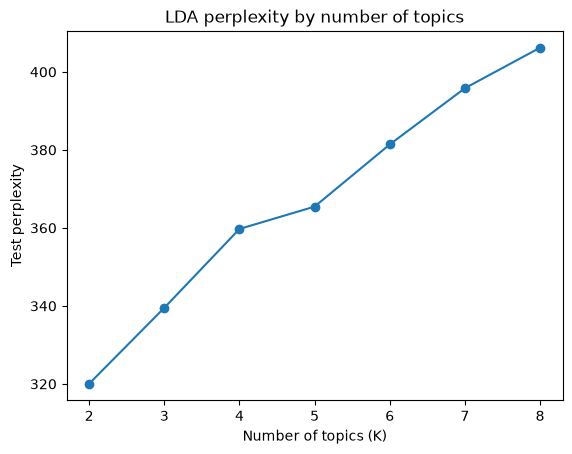

In [10]:
import matplotlib.pyplot as plt
from sklearn.decomposition import LatentDirichletAllocation

k_values = range(2, 9)
perplexities = []
for k in k_values:
    model = LatentDirichletAllocation(
        n_components=k, random_state=42, max_iter=20,
        learning_method='batch'
    )
    model.fit(X_train)
    perplexities.append(model.perplexity(X_test))
    print(k, perplexities[-1])

plt.plot(k_values, perplexities, marker='o')
plt.xlabel('Number of topics (K)')
plt.ylabel('Test perplexity')
plt.title('LDA perplexity by number of topics')
plt.show()

### Exercise 5(c) (2 points)

Based on the plot in part 5(b) and what you learned in class, which value of `K` would you choose? Justify your answer in two or three sentences. (Hint: perplexity is not the only criterion to consider.)

In [11]:
chosen_k = 2
print('Choose K=2 because it has the lowest test perplexity in the plot. Check topic coherence and interpretability as well, since a low perplexity alone does not guarantee useful topics.')

Choose K=2 because it has the lowest test perplexity in the plot. Check topic coherence and interpretability as well, since a low perplexity alone does not guarantee useful topics.


### Exercise 5(d) (3 points)

Fit a final LDA model with your chosen `K` on the training matrix (use `random_state=42`, `max_iter=50`, and `learning_method='batch'`) and print the ten most probable words of each topic.

In [12]:
lda_final = LatentDirichletAllocation(
    n_components=chosen_k, random_state=42, max_iter=50,
    learning_method='batch'
)
lda_final.fit(X_train)
words = np.array(count_vectorizer.get_feature_names_out())
for topic_number, topic in enumerate(lda_final.components_, start=1):
    print(f"Topic {topic_number}: {', '.join(words[topic.argsort()[-10:][::-1]])}")

Topic 1: acidity, fruit, finish, palate, fresh, aroma, apple, ripe, note, crisp
Topic 2: fruit, tannin, cherry, black, aroma, red, palate, finish, spice, berry


### Exercise 5(e) (3 points)

Using the model from part 5(d), compute the document-topic distribution of the training documents, assign each document to its dominant topic, and report the number of documents and the average `points` for each topic. Briefly comment on whether any topic is associated with higher-rated wines.

In [13]:
train_topics = lda_final.transform(X_train).argmax(axis=1)
topic_summary = train_df[['points']].copy()
topic_summary['topic'] = train_topics
topic_summary = topic_summary.groupby('topic')['points'].agg(
    documents='size', average_points='mean'
)
print(topic_summary)
overall_mean = train_df['points'].mean()
best_topic = topic_summary['average_points'].idxmax()
print(f"Topic {best_topic} has the highest mean points ({topic_summary.loc[best_topic, 'average_points']:.2f}) versus the overall mean ({overall_mean:.2f}).")

       documents  average_points
topic                           
0           1715         87.8000
1           2285         88.8814
Topic 1 has the highest mean points (88.88) versus the overall mean (88.42).
